# A BUSINESS INTELLIGENCE FRAMEWORK FOR YOUTUBE VIDEO PERFORMANCE PREDICTION AND STRATEGY RECOMMENDATION



**Install API packages**

In [ ]:
pip install google-api-python-client pandas

Extracting Data from YouTube API

In [ ]:
from googleapiclient.discovery import build
import pandas as pd

API_KEY = "YOUR_YOUTUBE_API_KEY"
youtube = build("youtube", "v3", developerKey=API_KEY)

def get_video_details(video_ids):
    all_data = []
    for i in range(0, len(video_ids), 250):  # API allows max 250 per request
        request = youtube.videos().list(
            part="snippet,statistics,contentDetails",
            id=",".join(video_ids[i:i+50])
        )
        response = request.execute()
        for item in response["items"]:
            data = {
                "video_id":      item["id"],
                "title":         item["snippet"]["title"],
                "category_id":   item["snippet"]["categoryId"],
                "published_at":  item["snippet"]["publishedAt"],
                "tags":          item["snippet"].get("tags", []),
                "description":   item["snippet"]["description"],
                "duration":      item["contentDetails"]["duration"],
                "views":         item["statistics"].get("viewCount", 0),
                "likes":         item["statistics"].get("likeCount", 0),
                "comments":      item["statistics"].get("commentCount", 0),
            }
            all_data.append(data)
    return pd.DataFrame(all_data)

In [ ]:
def search_videos(query, max_results=200):
    video_ids = []
    request = youtube.search().list(
        part="id",
        q=query,
        type="video",
        maxResults=50,
        relevanceLanguage="en"
    )
    response = request.execute()
    video_ids += [item["id"]["videoId"] for item in response["items"]]
    return video_ids

# Example: collect gaming videos
ids = search_videos("gaming tutorials", max_results=200)
df = get_video_details(ids)
df.to_csv("youtube_gaming_data.csv", index=False)
print(df.head())

      video_id                                              title category_id  \
0  EgAVfhgaCSo                      Video Game Tutorials be like…          24   
1  EwcKWsRCY-k     Modern Games Are Over-Tutorialized. Here's Why          20   
2  0tGhUExJCEI     How to Start Making Games (With NO Experience)          20   
3  tuBPW0xe5Gw                            Game Tutorials Be Like…          24   
4  _eK26atXTds  Everything You Need To Start Making Games (As ...          20   

           published_at                                               tags  \
0  2024-12-27T15:49:00Z                                                 []   
1  2026-02-17T04:45:35Z                                                 []   
2  2024-10-13T12:51:21Z  [gamedev, game development, how to make games,...   
3  2025-08-07T22:01:45Z                                                 []   
4  2024-11-22T19:00:19Z  [game development, game dev, gamemaker, indie ...   

                                         des

In [ ]:
categories = {
    "gaming_1":    "gaming videos 2024",
    "gaming_2":    "gaming tutorials",
    "gaming_3":    "gaming highlights",
    "cooking_1":   "cooking recipes",
    "cooking_2":   "easy recipes",
    "cooking_3":   "meal prep",
    "education_1": "educational tutorials",
    "education_2": "online learning",
    "education_3": "study tips",
    "tech_1":      "technology reviews",
    "tech_2":      "smartphone reviews",
    "tech_3":      "laptop reviews",
    "music_1":     "music covers",
    "music_2":     "piano tutorials",
    "fitness_1":   "workout videos",
    "fitness_2":   "yoga tutorials",
    "travel_1":    "travel vlogs",
    "travel_2":    "budget travel tips",
    "finance_1":   "personal finance tips",
    "finance_2":   "investing for beginners",
}

all_dfs = []
for cat_name, query in categories.items():
    print(f"Collecting: {cat_name}")
    ids = search_videos(query)
    df = get_video_details(ids)
    df["category_name"] = cat_name
    all_dfs.append(df)

final_df = pd.concat(all_dfs, ignore_index=True)
final_df.to_csv("youtube_full_dataset.csv", index=False)
print(f"Total videos collected: {len(final_df)}")

Collecting: gaming_1
Collecting: gaming_2
Collecting: gaming_3
Collecting: cooking_1
Collecting: cooking_2
Collecting: cooking_3
Collecting: education_1
Collecting: education_2
Collecting: education_3
Collecting: tech_1
Collecting: tech_2
Collecting: tech_3
Collecting: music_1
Collecting: music_2
Collecting: fitness_1
Collecting: fitness_2
Collecting: travel_1
Collecting: travel_2
Collecting: finance_1
Collecting: finance_2
Total videos collected: 973


In [ ]:
pip install openpyxl

# Import Dataset
Downloaded from Kaggle and combine with dataset extracted from offical YouTube API

In [ ]:
with pd.ExcelWriter("youtube_dataset.xlsx", engine="openpyxl") as writer:
    # All data on first sheet
    final_df.to_excel(writer, sheet_name="All Videos", index=False)

    # Each category on its own sheet
    for cat in final_df["category_name"].unique():
        cat_df = final_df[final_df["category_name"] == cat]
        cat_df.to_excel(writer, sheet_name=cat.capitalize(), index=False)

print("Excel file with multiple sheets saved!")

Excel file with multiple sheets saved!


Checking info about dataset

In [ ]:
import pandas as pd

# df = pd.read_excel("dataset.xlsx", encoding="utf-8", on_bad_lines="skip")
df = pd.read_excel("dataset.xlsx")

print(f"Total rows: {len(df)}")
print(f"Total columns: {len(df.columns)}")
print(f"\nColumn names and data types:")
print(df.dtypes)
print(f"\nFirst 3 rows:")
print(df.head(3))
print(f"\nMissing values:")
print(df.isnull().sum())

Total rows: 25535
Total columns: 20

Column names and data types:
index                            float64
video_id                          object
trending_date                     object
title                             object
channel_title                     object
category_id                      float64
category_name                    float64
publish_date              datetime64[ns]
time_frame                        object
published_day_of_week             object
publish_country                   object
tags                              object
views                            float64
likes                            float64
dislikes                         float64
comment_count                    float64
comments_disabled                   bool
ratings_disabled                    bool
video_error_or_removed              bool
Random_Number                    float64
dtype: object

First 3 rows:
      index     video_id trending_date  \
0  122181.0  v0ckHiILXLU      17.21.11   
1

# Phase A

**Data Cleaning**

**Check how many unique videos exist:**

In [ ]:
import pandas as pd

df = pd.read_csv("US_youtube_trending_data.csv",
                 encoding="utf-8",
                 on_bad_lines="skip",
                 engine="python")

print(f"Total rows: {len(df)}")
print(f"Unique video_ids: {df['video_id'].nunique()}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nViews stats:")
print(df["view_count"].describe())
print(f"\nFirst 3 rows:")
print(df.head(3))

Total rows: 111375
Unique video_ids: 20145

Columns: ['video_id', 'title', 'publishedAt', 'channelId', 'channelTitle', 'categoryId', 'trending_date', 'tags', 'view_count', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'description']

Views stats:
count    1.113750e+05
mean     2.712476e+06
std      7.040108e+06
min      0.000000e+00
25%      5.257075e+05
50%      1.082715e+06
75%      2.427272e+06
max      2.644074e+08
Name: view_count, dtype: float64

First 3 rows:
      video_id                                              title  \
0  3C66w5Z0ixs                 I ASKED HER TO BE MY GIRLFRIEND...   
1  M9Pmf9AB4Mo  Apex Legends | Stories from the Outlands – “Th...   
2  J78aPJ3VyNs  I left youtube for a month and THIS is what ha...   

            publishedAt                 channelId   channelTitle  categoryId  \
0  2020-08-11T19:20:14Z  UCvtRTOMP2TqYqu51xNrqAzg       Brawadis          22   
1  2020-08-11T17:00:10Z  UC0ZV6M2THA81QT9

In [ ]:
import pandas as pd
import numpy as np

# ── Load ──────────────────────────────────────────────────
df = pd.read_csv("US_youtube_trending_data.csv",
                 encoding="utf-8",
                 on_bad_lines="skip",
                 engine="python")

print(f"Original rows: {len(df)}")
print(f"Unique videos: {df['video_id'].nunique()}")

# ════════════════════════════════════════════════════════
# PHASE 1 — DATA CLEANING
# ════════════════════════════════════════════════════════

# ── Step 1: Drop unnecessary columns ─────────────────────
df.drop(columns=["channelId", "thumbnail_link", "description"], inplace=True)

# ── Step 2: Fix date columns ──────────────────────────────
df["publishedAt"]    = pd.to_datetime(df["publishedAt"],    errors="coerce", utc=True)
df["trending_date"]  = pd.to_datetime(df["trending_date"],  errors="coerce", utc=True)

# ── Step 3: Fix numeric columns ───────────────────────────
for col in ["view_count", "likes", "dislikes", "comment_count"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# ── Step 4: Remove rows with 0 or NaN views ──────────────
df = df[df["view_count"] > 0]
df.dropna(subset=["view_count"], inplace=True)
print(f"After removing zero/NaN views: {len(df)} rows")

# ── Step 5: Fill missing numeric values ───────────────────
for col in ["likes", "dislikes", "comment_count"]:
    df[col] = df[col].fillna(df[col].median())

# ── Step 6: Keep MAX views row per video ──────────────────
df = df.sort_values("view_count", ascending=False)
df = df.drop_duplicates(subset="video_id", keep="first")
print(f"After deduplication (peak views): {len(df)} rows")

# ── Step 7: Map category names ────────────────────────────
category_map = {
    1:"Film & Animation", 2:"Autos & Vehicles", 10:"Music",
    15:"Pets & Animals", 17:"Sports", 18:"Short Movies",
    19:"Travel & Events", 20:"Gaming", 21:"Videoblogging",
    22:"People & Blogs", 23:"Comedy", 24:"Entertainment",
    25:"News & Politics", 26:"Howto & Style", 27:"Education",
    28:"Science & Technology", 29:"Nonprofits & Activism",
    30:"Movies", 43:"Shows", 44:"Trailers"
}
df["category_name"] = df["categoryId"].map(category_map)
df["category_name"] = df["category_name"].fillna("Unknown")

# ── Step 8: Fix tags ──────────────────────────────────────
df["tags"] = df["tags"].fillna("no tags")

# ── Step 9: Remove extreme outliers (top 0.1%) ───────────
upper = df["view_count"].quantile(0.999)
df    = df[df["view_count"] <= upper]
print(f"After removing outliers: {len(df)} rows")

print(f"\nCleaning complete: {len(df)} rows")


Original rows: 268787
Unique videos: 47142
After removing zero/NaN views: 268707 rows
After deduplication (peak views): 47124 rows
After removing outliers: 47076 rows

Cleaning complete: 47076 rows


# PHASE B
**Feature Engineering**

In [ ]:

# ════════════════════════════════════════════════════════
# PHASE 2 — FEATURE ENGINEERING
# ════════════════════════════════════════════════════════

# ── Temporal features ─────────────────────────────────────
df["publish_hour"]    = df["publishedAt"].dt.hour
df["publish_day"]     = df["publishedAt"].dt.day_name()
df["publish_month"]   = df["publishedAt"].dt.month
df["publish_year"]    = df["publishedAt"].dt.year

# ── Days from publish to trending ─────────────────────────
df["days_to_trending"] = (
    df["trending_date"] - df["publishedAt"]
).dt.total_seconds() / 86400
df["days_to_trending"] = df["days_to_trending"].clip(lower=0)

# ── Content features ──────────────────────────────────────
df["title_length"]    = df["title"].apply(lambda x: len(str(x).split()))
df["title_char_count"]= df["title"].apply(lambda x: len(str(x)))
df["tag_count"]       = df["tags"].apply(
    lambda x: len(str(x).split("|")) if x != "no tags" else 0
)
df["has_tags"]        = (df["tag_count"] > 0).astype(int)

# ── Engagement KPIs ───────────────────────────────────────
df["engagement_rate"] = (
    (df["likes"] + df["comment_count"]) / df["view_count"] * 100
).round(4)

df["like_ratio"]      = (df["likes"]         / df["view_count"]).round(4)
df["dislike_ratio"]   = (df["dislikes"]       / df["view_count"]).round(4)
df["comment_ratio"]   = (df["comment_count"]  / df["view_count"]).round(4)

# ── Boolean to int ────────────────────────────────────────
df["comments_disabled"] = df["comments_disabled"].astype(int)
df["ratings_disabled"]  = df["ratings_disabled"].astype(int)



# PHASE C

In [ ]:
# ════════════════════════════════════════════════════════
# PHASE 3 — SUCCESS CLASSIFICATION
# ════════════════════════════════════════════════════════

Q30 = df["view_count"].quantile(0.30)
Q70 = df["view_count"].quantile(0.70)

def classify_success(views):
    if views < Q30:
        return "Low"
    elif views <= Q70:
        return "Medium"
    else:
        return "High"

df["success_class"] = df["view_count"].apply(classify_success)

print(f"\nSuccess class thresholds:")
print(f"Q30 (Low/Medium boundary):   {Q30:,.0f} views")
print(f"Q70 (Medium/High boundary):  {Q70:,.0f} views")
print(f"\nSuccess class distribution:")
print(df["success_class"].value_counts())

# ════════════════════════════════════════════════════════
# FINAL SUMMARY
# ════════════════════════════════════════════════════════

print(f"\n{'='*55}")
print(f"FINAL DATASET: {len(df)} rows, {len(df.columns)} columns")
print(f"{'='*55}")

print(f"\nCategory distribution:")
print(df["category_name"].value_counts())

print(f"\nTop publish days:")
print(df["publish_day"].value_counts())

print(f"\nTop publish hours:")
print(df["publish_hour"].value_counts().sort_index())

print(f"\nEngagement rate stats:")
print(df["engagement_rate"].describe())

print(f"\nMissing values:")
print(df.isnull().sum())

print(f"\nFinal columns:")
print(df.columns.tolist())

# ── Save ──────────────────────────────────────────────────
df.to_csv("youtube_final.csv", index=False)
df.to_excel("youtube_final.xlsx", index=False)
print(f"\nSaved as youtube_final.csv and youtube_final.xlsx")


Success class thresholds:
Q30 (Low/Medium boundary):   619,542 views
Q70 (Medium/High boundary):  1,934,870 views

Success class distribution:
success_class
Medium    18830
High      14123
Low       14123
Name: count, dtype: int64

FINAL DATASET: 47076 rows, 28 columns

Category distribution:
category_name
Gaming                   9432
Entertainment            9154
Music                    7332
Sports                   6072
People & Blogs           4032
Comedy                   2254
Film & Animation         1831
News & Politics          1732
Science & Technology     1424
Howto & Style            1216
Education                1112
Autos & Vehicles          967
Travel & Events           292
Pets & Animals            207
Nonprofits & Activism      19
Name: count, dtype: int64

Top publish days:
publish_day
Friday       7654
Tuesday      7035
Wednesday    6880
Monday       6797
Sunday       6485
Thursday     6418
Saturday     5807
Name: count, dtype: int64

Top publish hours:
publish_hour

ValueError: Excel does not support datetimes with timezones. Please ensure that datetimes are timezone unaware before writing to Excel.

In [ ]:
# Fix timezone issue for Excel export
df["publishedAt"]   = df["publishedAt"].dt.tz_localize(None)
df["trending_date"] = df["trending_date"].dt.tz_localize(None)

# Save again — this overwrites the broken Excel file
df.to_excel("youtube_final.xlsx", index=False)
print("Excel saved successfully!")

Excel saved successfully!


In [ ]:
import pandas as pd

df = pd.read_csv("youtube_final.csv")
df["publishedAt"]   = pd.to_datetime(df["publishedAt"])
df["trending_date"] = pd.to_datetime(df["trending_date"])

print(f"Dataset loaded: {len(df)} rows, {len(df.columns)} columns")
print("Ready to continue!")

Dataset loaded: 47076 rows, 28 columns
Ready to continue!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Set plot style
plt.style.use("seaborn-v0_8")
sns.set_palette("husl")

# Load dataset
df = pd.read_csv("youtube_final.csv")
df["publishedAt"]   = pd.to_datetime(df["publishedAt"])
df["trending_date"] = pd.to_datetime(df["trending_date"])

print(f"Dataset loaded: {len(df)} rows, {len(df.columns)} columns")
print(f"Columns: {df.columns.tolist()}")
print(f"\nSuccess class distribution:")
print(df["success_class"].value_counts())
print(f"\nReady to start EDA!")

Dataset loaded: 47076 rows, 28 columns
Columns: ['video_id', 'title', 'publishedAt', 'channelTitle', 'categoryId', 'trending_date', 'tags', 'view_count', 'likes', 'dislikes', 'comment_count', 'comments_disabled', 'ratings_disabled', 'category_name', 'publish_hour', 'publish_day', 'publish_month', 'publish_year', 'days_to_trending', 'title_length', 'title_char_count', 'tag_count', 'has_tags', 'engagement_rate', 'like_ratio', 'dislike_ratio', 'comment_ratio', 'success_class']

Success class distribution:
success_class
Medium    18830
High      14123
Low       14123
Name: count, dtype: int64

Ready to start EDA!


# PHASE D

**Basic Statistics Overview**

In [ ]:
# ── Basic Statistics ──────────────────────────────────────
print("=" * 55)
print("BASIC DATASET STATISTICS")
print("=" * 55)

# Key metrics summary
key_cols = ["view_count", "likes", "dislikes",
            "comment_count", "engagement_rate",
            "days_to_trending", "tag_count", "title_length"]

print(df[key_cols].describe().round(2))

print(f"\nKey Insights:")
print(f"Average views:          {df['view_count'].mean():,.0f}")
print(f"Median views:           {df['view_count'].median():,.0f}")
print(f"Average likes:          {df['likes'].mean():,.0f}")
print(f"Average engagement:     {df['engagement_rate'].mean():.2f}%")
print(f"Avg days to trending:   {df['days_to_trending'].mean():.1f} days")
print(f"Avg title length:       {df['title_length'].mean():.1f} words")
print(f"Avg tag count:          {df['tag_count'].mean():.1f} tags")
print(f"Videos with tags:       {df['has_tags'].sum():,} ({df['has_tags'].mean()*100:.1f}%)")
print(f"Comments disabled:      {df['comments_disabled'].sum():,} videos")
print(f"Ratings disabled:       {df['ratings_disabled'].sum():,} videos")

BASIC DATASET STATISTICS
         view_count       likes   dislikes  comment_count  engagement_rate  \
count  4.707600e+04    47076.00   47076.00       47076.00         47076.00   
mean   2.496130e+06   112844.28    1122.36        8111.68             5.10   
std    5.333154e+06   280187.08    6129.71       38764.79             3.50   
min    2.225300e+04        0.00       0.00           0.00             0.00   
25%    5.388708e+05    18261.75       0.00        1290.00             2.53   
50%    1.065606e+06    41565.50       0.00        2745.00             4.54   
75%    2.317956e+06   101191.00     512.00        6170.00             6.76   
max    1.035642e+08  9444379.00  467717.00     3431431.00            39.40   

       days_to_trending  tag_count  title_length  
count          47076.00   47076.00      47076.00  
mean               5.63      16.20          8.88  
std                1.87      12.55          3.67  
min                0.00       1.00          1.00  
25%              

**Views Distribution Plot**

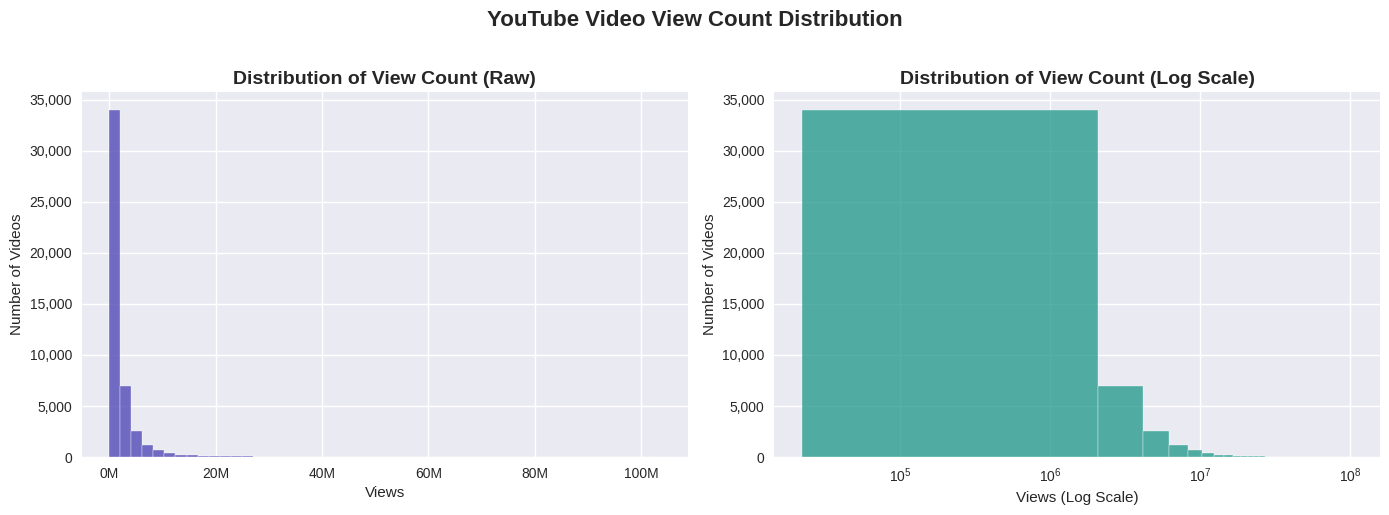

Saved: views_distribution.png


In [ ]:
# ── Views Distribution ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Raw views distribution
axes[0].hist(df["view_count"], bins=50, color="#534AB7", edgecolor="white", alpha=0.8)
axes[0].set_title("Distribution of View Count (Raw)", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Views")
axes[0].set_ylabel("Number of Videos")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x/1e6)}M"))

# Plot 2: Log-scale views distribution
axes[1].hist(df["view_count"], bins=50, color="#2A9D8F", edgecolor="white", alpha=0.8)
axes[1].set_xscale("log")
axes[1].set_title("Distribution of View Count (Log Scale)", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Views (Log Scale)")
axes[1].set_ylabel("Number of Videos")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.suptitle("YouTube Video View Count Distribution", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("views_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: views_distribution.png")

**Success Class Distribution**

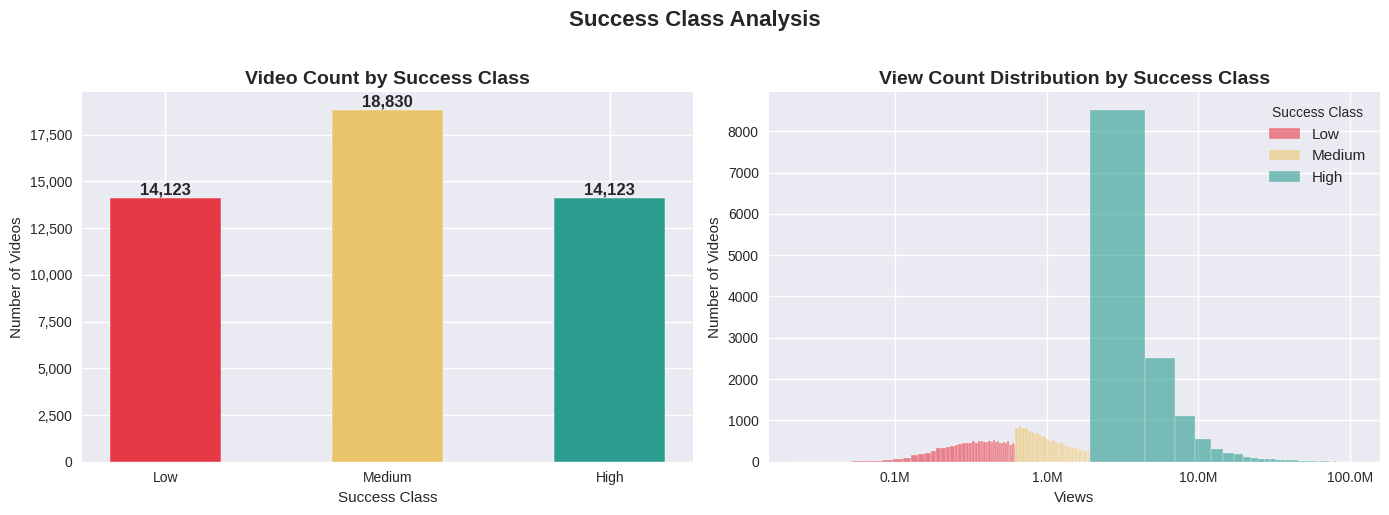

Success Class Thresholds:
Low    →  Views below  619,542
Medium →  Views between 619,542 and 1,934,870
High   →  Views above  1,934,870

Saved: success_class_distribution.png


In [ ]:
# ── Success Class Distribution ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Bar chart of success class counts
colors = ["#E63946", "#E9C46A", "#2A9D8F"]
class_counts = df["success_class"].value_counts().reindex(["Low", "Medium", "High"])

axes[0].bar(class_counts.index, class_counts.values,
            color=colors, edgecolor="white", width=0.5)
axes[0].set_title("Video Count by Success Class", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Success Class")
axes[0].set_ylabel("Number of Videos")
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 200, f"{v:,}", ha="center", fontweight="bold", fontsize=12)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))

# Plot 2: View count distribution by success class
for cls, color in zip(["Low", "Medium", "High"], colors):
    subset = df[df["success_class"] == cls]["view_count"]
    axes[1].hist(subset, bins=40, alpha=0.6, color=color, label=cls, edgecolor="white")

axes[1].set_title("View Count Distribution by Success Class", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Views")
axes[1].set_ylabel("Number of Videos")
axes[1].set_xscale("log")
axes[1].legend(title="Success Class", fontsize=11)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))

plt.suptitle("Success Class Analysis", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("success_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Print thresholds
Q30 = df["view_count"].quantile(0.30)
Q70 = df["view_count"].quantile(0.70)
print(f"Success Class Thresholds:")
print(f"Low    →  Views below  {Q30:,.0f}")
print(f"Medium →  Views between {Q30:,.0f} and {Q70:,.0f}")
print(f"High   →  Views above  {Q70:,.0f}")
print(f"\nSaved: success_class_distribution.png")

**Category-Wise Performance Analysis**

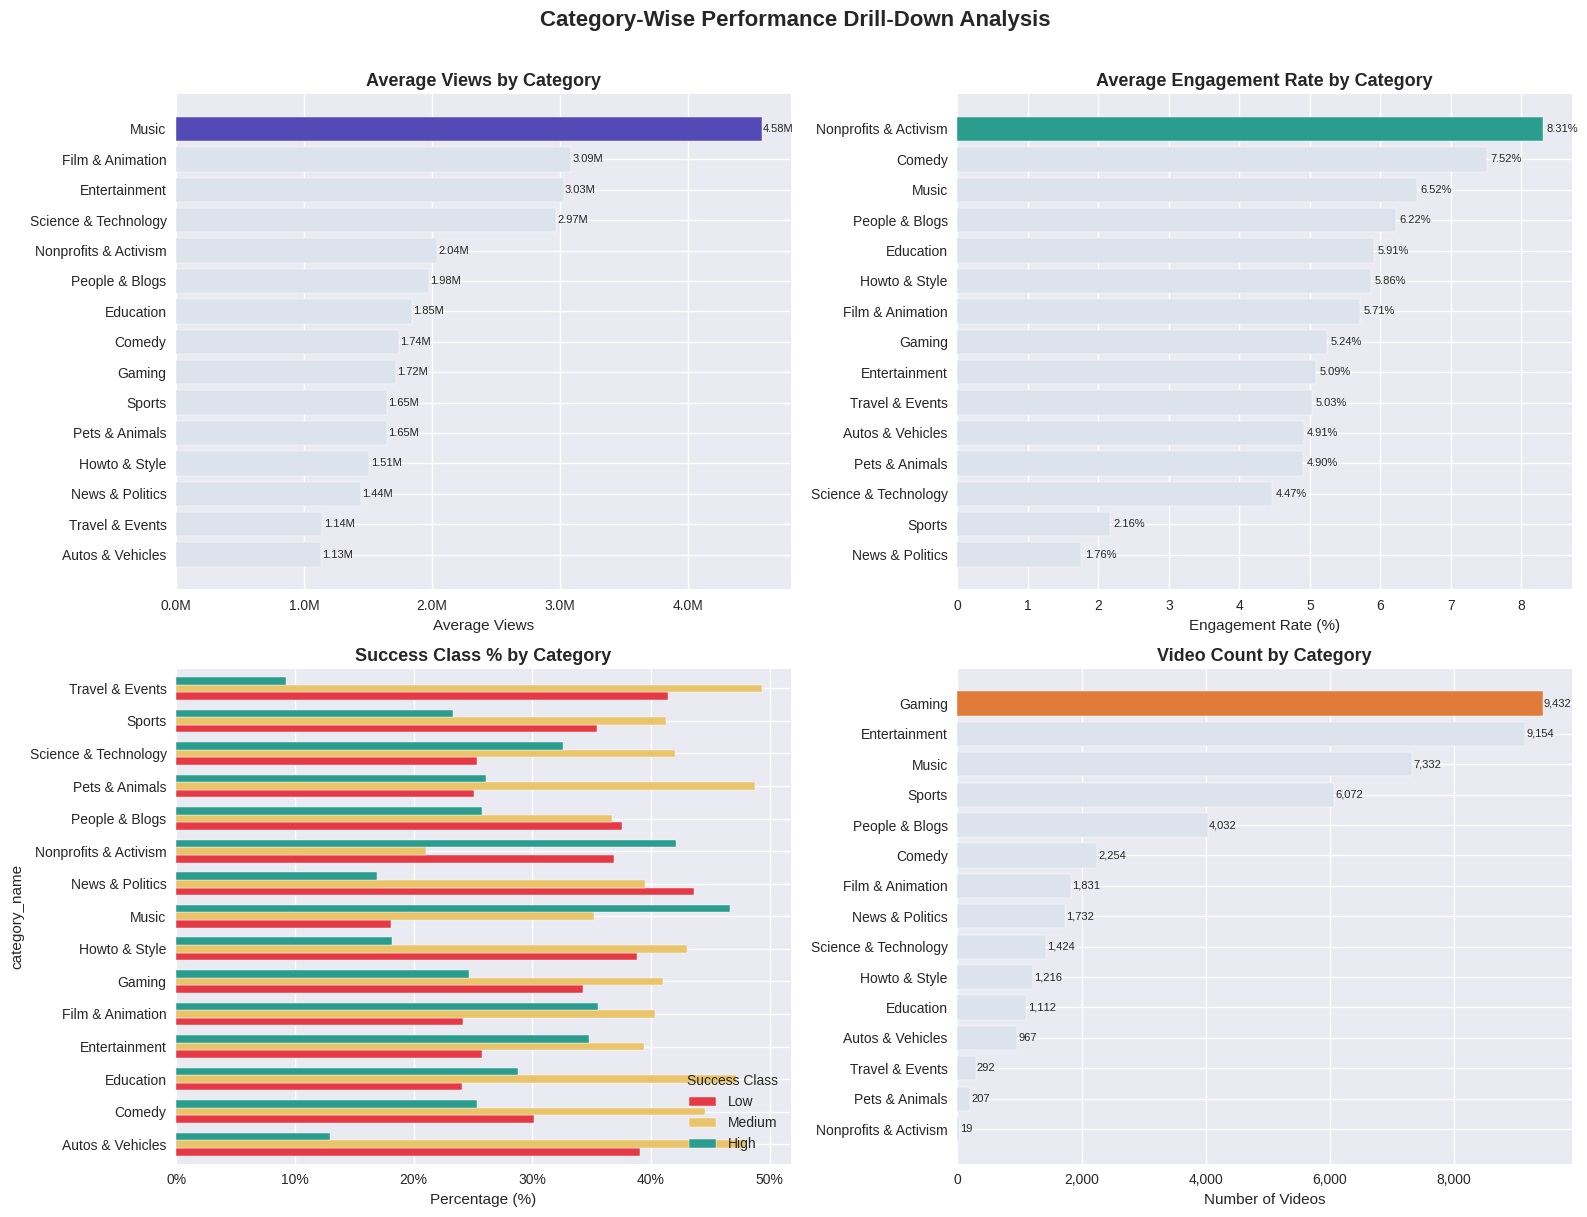

Category Performance Summary:
                       Total_Videos Avg_Views  Avg_Engagement  Avg_Likes  High_Pct
category_name                                                                     
Music                          7332     4.58M            6.52  245992.00     46.67
Film & Animation               1831     3.09M            5.71  108842.38     35.50
Entertainment                  9154     3.03M            5.09  129323.93     34.79
Science & Technology           1424     2.97M            4.47  103683.23     32.58
Nonprofits & Activism            19     2.04M            8.31  164082.47     42.11
People & Blogs                 4032     1.98M            6.22  102640.93     25.79
Education                      1112     1.85M            5.91   93984.01     28.78
Comedy                         2254     1.74M            7.52  118109.15     25.33
Gaming                         9432     1.72M            5.24   83366.56     24.67
Sports                         6072     1.65M            

In [ ]:
# ── Category-Wise Drill-Down Analysis ────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ── Chart 1: Average views by category ───────────────────
cat_views = df.groupby("category_name")["view_count"].mean().sort_values(ascending=True)
colors_bar = ["#534AB7" if v == cat_views.max() else "#DDE3EC" for v in cat_views.values]

axes[0,0].barh(cat_views.index, cat_views.values, color=colors_bar, edgecolor="white")
axes[0,0].set_title("Average Views by Category", fontsize=13, fontweight="bold")
axes[0,0].set_xlabel("Average Views")
axes[0,0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
for i, v in enumerate(cat_views.values):
    axes[0,0].text(v + 10000, i, f"{v/1e6:.2f}M", va="center", fontsize=8)

# ── Chart 2: Average engagement rate by category ─────────
cat_eng = df.groupby("category_name")["engagement_rate"].mean().sort_values(ascending=True)
colors_eng = ["#2A9D8F" if v == cat_eng.max() else "#DDE3EC" for v in cat_eng.values]

axes[0,1].barh(cat_eng.index, cat_eng.values, color=colors_eng, edgecolor="white")
axes[0,1].set_title("Average Engagement Rate by Category", fontsize=13, fontweight="bold")
axes[0,1].set_xlabel("Engagement Rate (%)")
for i, v in enumerate(cat_eng.values):
    axes[0,1].text(v + 0.05, i, f"{v:.2f}%", va="center", fontsize=8)

# ── Chart 3: Success class distribution by category ──────
cat_success = df.groupby(["category_name", "success_class"]).size().unstack(fill_value=0)
cat_success = cat_success.reindex(columns=["Low", "Medium", "High"])
cat_success_pct = cat_success.div(cat_success.sum(axis=1), axis=0) * 100

cat_success_pct.plot(kind="barh", ax=axes[1,0],
                      color=["#E63946", "#E9C46A", "#2A9D8F"],
                      edgecolor="white", width=0.7)
axes[1,0].set_title("Success Class % by Category", fontsize=13, fontweight="bold")
axes[1,0].set_xlabel("Percentage (%)")
axes[1,0].legend(title="Success Class", loc="lower right")
axes[1,0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))

# ── Chart 4: Video count by category ─────────────────────
cat_count = df["category_name"].value_counts().sort_values(ascending=True)
colors_count = ["#E07B39" if v == cat_count.max() else "#DDE3EC" for v in cat_count.values]

axes[1,1].barh(cat_count.index, cat_count.values, color=colors_count, edgecolor="white")
axes[1,1].set_title("Video Count by Category", fontsize=13, fontweight="bold")
axes[1,1].set_xlabel("Number of Videos")
axes[1,1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
for i, v in enumerate(cat_count.values):
    axes[1,1].text(v + 20, i, f"{v:,}", va="center", fontsize=8)

plt.suptitle("Category-Wise Performance Drill-Down Analysis",
             fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("category_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

# Print summary table
print("Category Performance Summary:")
print("=" * 65)
cat_summary = df.groupby("category_name").agg(
    Total_Videos    = ("video_id",        "count"),
    Avg_Views       = ("view_count",      "mean"),
    Avg_Engagement  = ("engagement_rate", "mean"),
    Avg_Likes       = ("likes",           "mean"),
    High_Pct        = ("success_class",   lambda x: (x == "High").mean() * 100)
).round(2).sort_values("Avg_Views", ascending=False)

cat_summary["Avg_Views"] = cat_summary["Avg_Views"].apply(lambda x: f"{x/1e6:.2f}M")
print(cat_summary.to_string())
print("\nSaved: category_analysis.png")

**Publish Day and Hour Analysis**

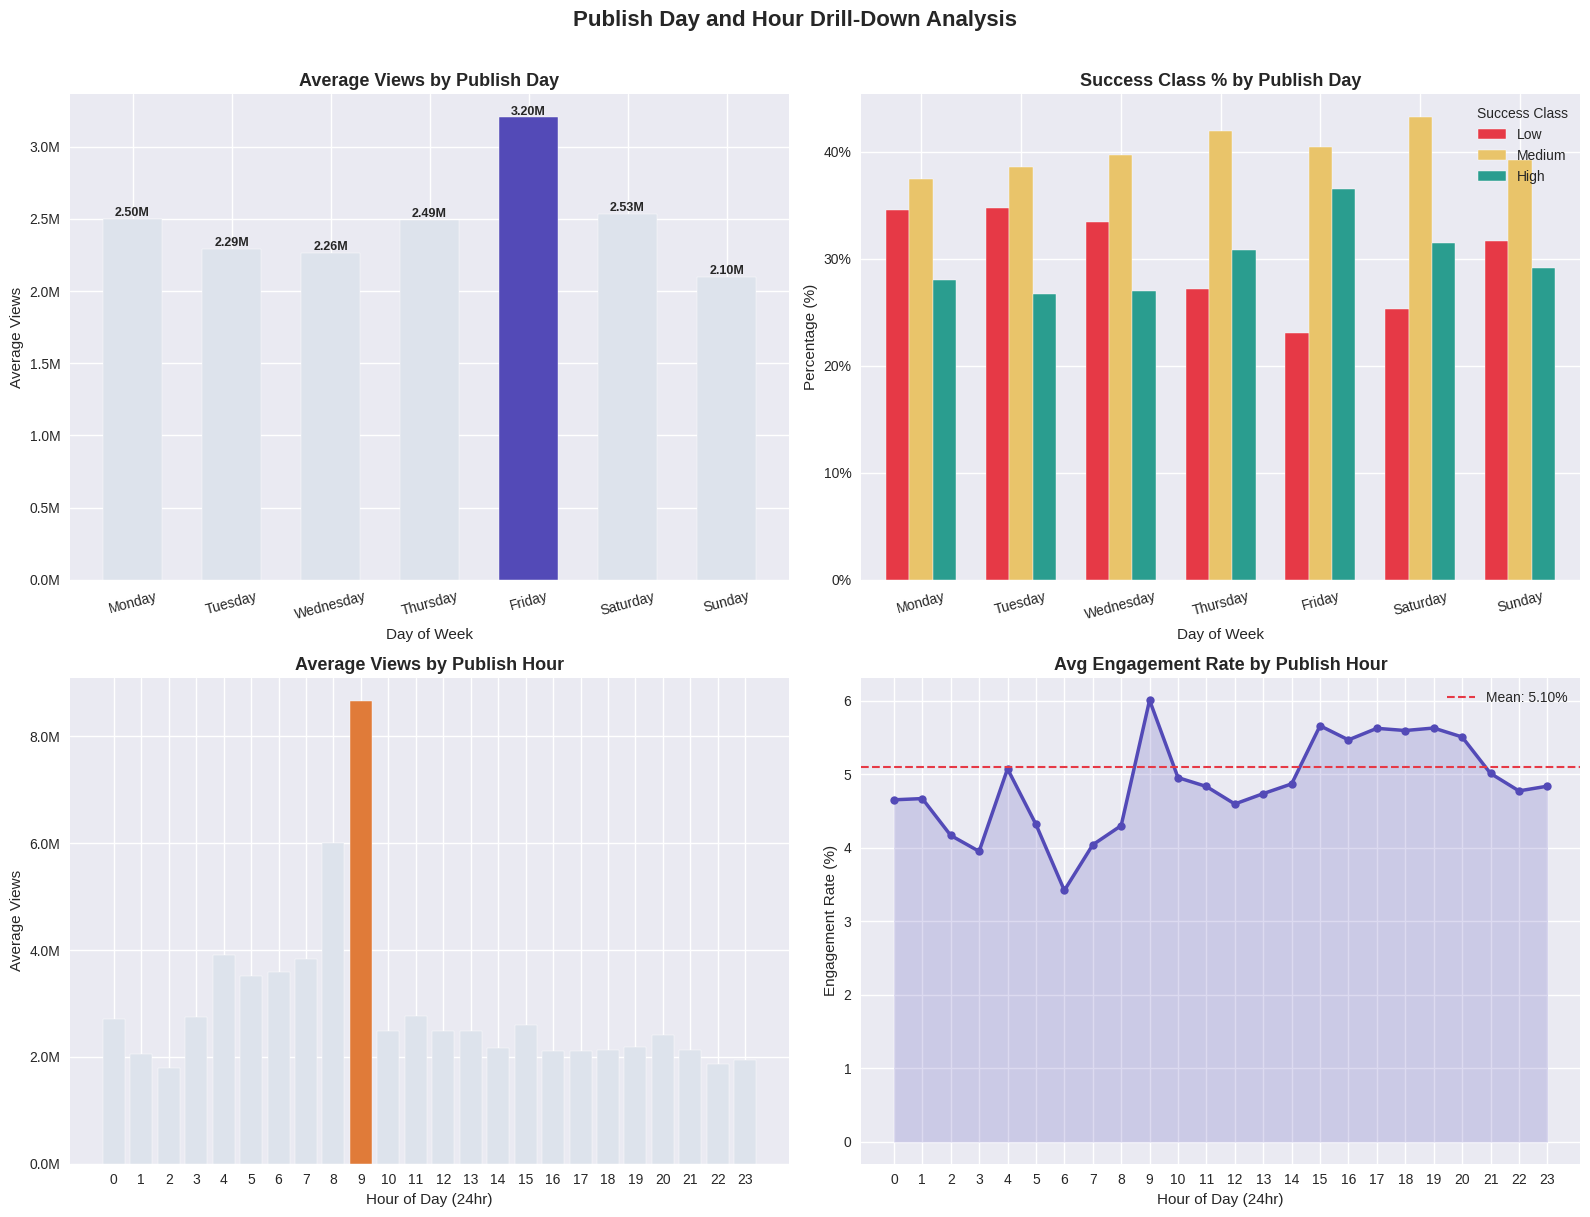

Average Views by Publish Day:
Monday       Avg Views: 2.50M  |  High %: 28.0%
Tuesday      Avg Views: 2.29M  |  High %: 26.7%
Wednesday    Avg Views: 2.26M  |  High %: 26.9%
Thursday     Avg Views: 2.49M  |  High %: 30.9%
Friday       Avg Views: 3.20M  |  High %: 36.5%
Saturday     Avg Views: 2.53M  |  High %: 31.5%
Sunday       Avg Views: 2.10M  |  High %: 29.2%

Best publish hour (avg views):
Hour 9:00  →  8.66M avg views

Best publish hour (engagement):
Hour 9:00  →  6.01% avg engagement

Saved: publish_timing_analysis.png


In [ ]:
# ── Publish Day and Hour Drill-Down ───────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ── Chart 1: Average views by publish day ─────────────────
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
day_views = df.groupby("publish_day")["view_count"].mean().reindex(day_order)
colors_day = ["#534AB7" if v == day_views.max() else "#DDE3EC" for v in day_views.values]

axes[0,0].bar(day_views.index, day_views.values, color=colors_day, edgecolor="white", width=0.6)
axes[0,0].set_title("Average Views by Publish Day", fontsize=13, fontweight="bold")
axes[0,0].set_xlabel("Day of Week")
axes[0,0].set_ylabel("Average Views")
axes[0,0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
for i, v in enumerate(day_views.values):
    axes[0,0].text(i, v + 20000, f"{v/1e6:.2f}M", ha="center", fontsize=9, fontweight="bold")
axes[0,0].tick_params(axis="x", rotation=15)

# ── Chart 2: Success class by publish day ─────────────────
day_success = df.groupby(["publish_day","success_class"]).size().unstack(fill_value=0)
day_success = day_success.reindex(day_order)
day_success_pct = day_success.div(day_success.sum(axis=1), axis=0) * 100
day_success_pct = day_success_pct.reindex(columns=["Low","Medium","High"])

day_success_pct.plot(kind="bar", ax=axes[0,1],
                     color=["#E63946","#E9C46A","#2A9D8F"],
                     edgecolor="white", width=0.7)
axes[0,1].set_title("Success Class % by Publish Day", fontsize=13, fontweight="bold")
axes[0,1].set_xlabel("Day of Week")
axes[0,1].set_ylabel("Percentage (%)")
axes[0,1].legend(title="Success Class")
axes[0,1].tick_params(axis="x", rotation=15)
axes[0,1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))

# ── Chart 3: Average views by publish hour ────────────────
hour_views = df.groupby("publish_hour")["view_count"].mean()
colors_hour = ["#E07B39" if v == hour_views.max() else "#DDE3EC" for v in hour_views.values]

axes[1,0].bar(hour_views.index, hour_views.values, color=colors_hour, edgecolor="white")
axes[1,0].set_title("Average Views by Publish Hour", fontsize=13, fontweight="bold")
axes[1,0].set_xlabel("Hour of Day (24hr)")
axes[1,0].set_ylabel("Average Views")
axes[1,0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
axes[1,0].set_xticks(range(0, 24))

# ── Chart 4: Engagement rate by publish hour ──────────────
hour_eng = df.groupby("publish_hour")["engagement_rate"].mean()
axes[1,1].plot(hour_eng.index, hour_eng.values,
               color="#534AB7", linewidth=2.5, marker="o", markersize=6)
axes[1,1].fill_between(hour_eng.index, hour_eng.values, alpha=0.2, color="#534AB7")
axes[1,1].set_title("Avg Engagement Rate by Publish Hour", fontsize=13, fontweight="bold")
axes[1,1].set_xlabel("Hour of Day (24hr)")
axes[1,1].set_ylabel("Engagement Rate (%)")
axes[1,1].set_xticks(range(0, 24))
axes[1,1].axhline(y=df["engagement_rate"].mean(),
                   color="#E63946", linestyle="--", linewidth=1.5, label=f"Mean: {df['engagement_rate'].mean():.2f}%")
axes[1,1].legend()

plt.suptitle("Publish Day and Hour Drill-Down Analysis",
             fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("publish_timing_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

# Print summary
print("Average Views by Publish Day:")
print("=" * 40)
for day in day_order:
    avg = df[df["publish_day"] == day]["view_count"].mean()
    high_pct = (df[df["publish_day"] == day]["success_class"] == "High").mean() * 100
    print(f"{day:<12} Avg Views: {avg/1e6:.2f}M  |  High %: {high_pct:.1f}%")

print(f"\nBest publish hour (avg views):")
best_hour = hour_views.idxmax()
print(f"Hour {best_hour}:00  →  {hour_views.max()/1e6:.2f}M avg views")

print(f"\nBest publish hour (engagement):")
best_eng_hour = hour_eng.idxmax()
print(f"Hour {best_eng_hour}:00  →  {hour_eng.max():.2f}% avg engagement")
print("\nSaved: publish_timing_analysis.png")

**Engagement Rate Deep Dive**

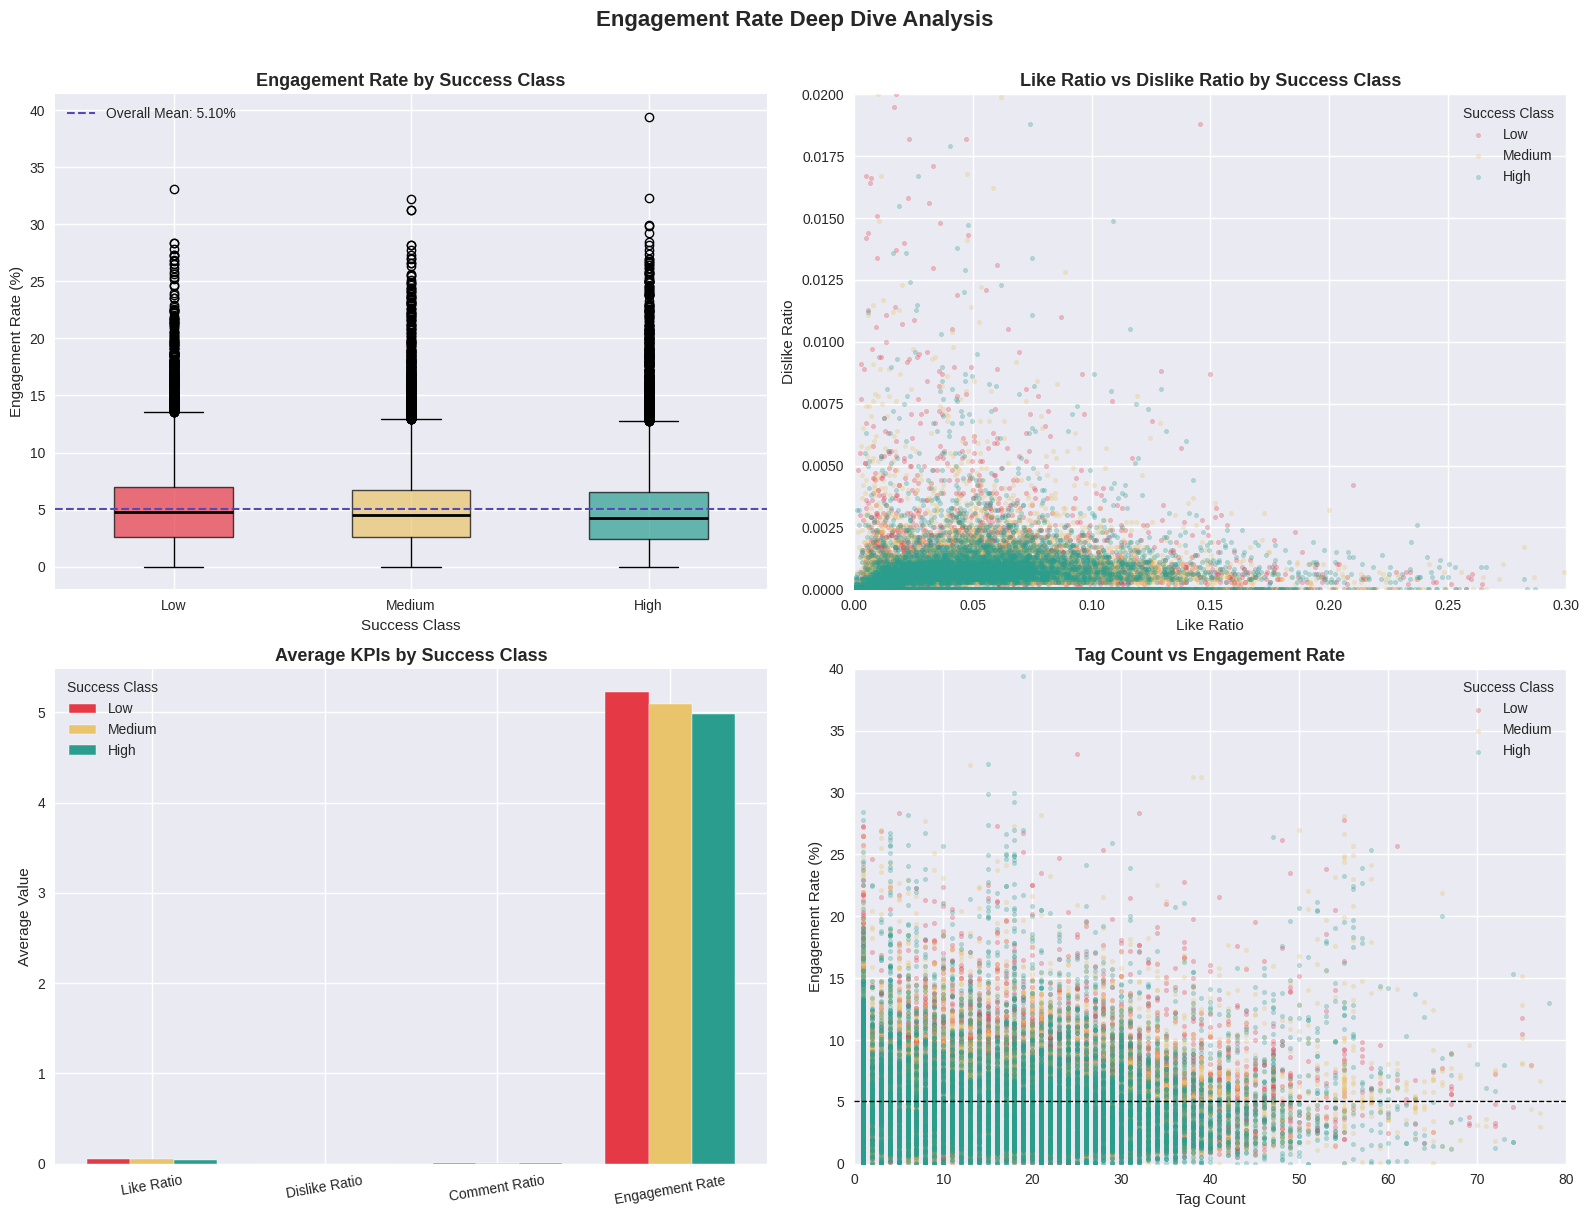

Average KPIs by Success Class:
              view_count    likes  engagement_rate  like_ratio  comment_ratio  days_to_trending
success_class                                                                                  
Low                0.39M   18,997           5.2199      0.0477         0.0045            5.0793
Medium             1.13M   53,483           5.0882      0.0474         0.0035            5.5507
High               6.42M  285,838           4.9838      0.0468         0.0031            6.2809

Saved: engagement_analysis.png


In [ ]:
# ── Engagement Rate Analysis ──────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ── Chart 1: Engagement rate by success class (boxplot) ───
colors_box = {"Low":"#E63946", "Medium":"#E9C46A", "High":"#2A9D8F"}
for i, cls in enumerate(["Low", "Medium", "High"]):
    data = df[df["success_class"] == cls]["engagement_rate"]
    axes[0,0].boxplot(data, positions=[i], widths=0.5,
                      patch_artist=True,
                      boxprops=dict(facecolor=colors_box[cls], alpha=0.7),
                      medianprops=dict(color="black", linewidth=2))

axes[0,0].set_xticks([0,1,2])
axes[0,0].set_xticklabels(["Low","Medium","High"])
axes[0,0].set_title("Engagement Rate by Success Class", fontsize=13, fontweight="bold")
axes[0,0].set_xlabel("Success Class")
axes[0,0].set_ylabel("Engagement Rate (%)")
axes[0,0].axhline(y=df["engagement_rate"].mean(),
                   color="#534AB7", linestyle="--", linewidth=1.5,
                   label=f"Overall Mean: {df['engagement_rate'].mean():.2f}%")
axes[0,0].legend()

# ── Chart 2: Like ratio vs dislike ratio by success class ─
for cls, color in zip(["Low","Medium","High"], ["#E63946","#E9C46A","#2A9D8F"]):
    subset = df[df["success_class"] == cls]
    axes[0,1].scatter(subset["like_ratio"], subset["dislike_ratio"],
                      alpha=0.3, color=color, label=cls, s=10)
axes[0,1].set_title("Like Ratio vs Dislike Ratio by Success Class",
                     fontsize=13, fontweight="bold")
axes[0,1].set_xlabel("Like Ratio")
axes[0,1].set_ylabel("Dislike Ratio")
axes[0,1].legend(title="Success Class")
axes[0,1].set_xlim(0, 0.3)
axes[0,1].set_ylim(0, 0.02)

# ── Chart 3: Avg KPIs by success class (grouped bar) ──────
kpi_cols  = ["like_ratio","dislike_ratio","comment_ratio","engagement_rate"]
kpi_names = ["Like Ratio","Dislike Ratio","Comment Ratio","Engagement Rate"]
kpi_by_class = df.groupby("success_class")[kpi_cols].mean().reindex(["Low","Medium","High"])

x     = np.arange(len(kpi_names))
width = 0.25
for i, (cls, color) in enumerate(zip(["Low","Medium","High"],
                                      ["#E63946","#E9C46A","#2A9D8F"])):
    axes[1,0].bar(x + i*width, kpi_by_class.loc[cls], width,
                  label=cls, color=color, edgecolor="white")

axes[1,0].set_title("Average KPIs by Success Class", fontsize=13, fontweight="bold")
axes[1,0].set_xticks(x + width)
axes[1,0].set_xticklabels(kpi_names, rotation=10)
axes[1,0].set_ylabel("Average Value")
axes[1,0].legend(title="Success Class")

# ── Chart 4: Tag count vs engagement rate (scatter) ───────
for cls, color in zip(["Low","Medium","High"], ["#E63946","#E9C46A","#2A9D8F"]):
    subset = df[df["success_class"] == cls]
    axes[1,1].scatter(subset["tag_count"], subset["engagement_rate"],
                      alpha=0.3, color=color, label=cls, s=10)
axes[1,1].set_title("Tag Count vs Engagement Rate", fontsize=13, fontweight="bold")
axes[1,1].set_xlabel("Tag Count")
axes[1,1].set_ylabel("Engagement Rate (%)")
axes[1,1].set_xlim(0, 80)
axes[1,1].set_ylim(0, 40)
axes[1,1].legend(title="Success Class")
axes[1,1].axhline(y=df["engagement_rate"].mean(),
                   color="black", linestyle="--", linewidth=1,
                   label=f"Mean: {df['engagement_rate'].mean():.2f}%")

plt.suptitle("Engagement Rate Deep Dive Analysis",
             fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("engagement_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

# Print KPI summary
print("Average KPIs by Success Class:")
print("=" * 60)
kpi_summary = df.groupby("success_class")[
    ["view_count","likes","engagement_rate",
     "like_ratio","comment_ratio","days_to_trending"]
].mean().reindex(["Low","Medium","High"]).round(4)

kpi_summary["view_count"] = kpi_summary["view_count"].apply(lambda x: f"{x/1e6:.2f}M")
kpi_summary["likes"]      = kpi_summary["likes"].apply(lambda x: f"{x:,.0f}")
print(kpi_summary.to_string())
print("\nSaved: engagement_analysis.png")

**Correlation Heatmap**

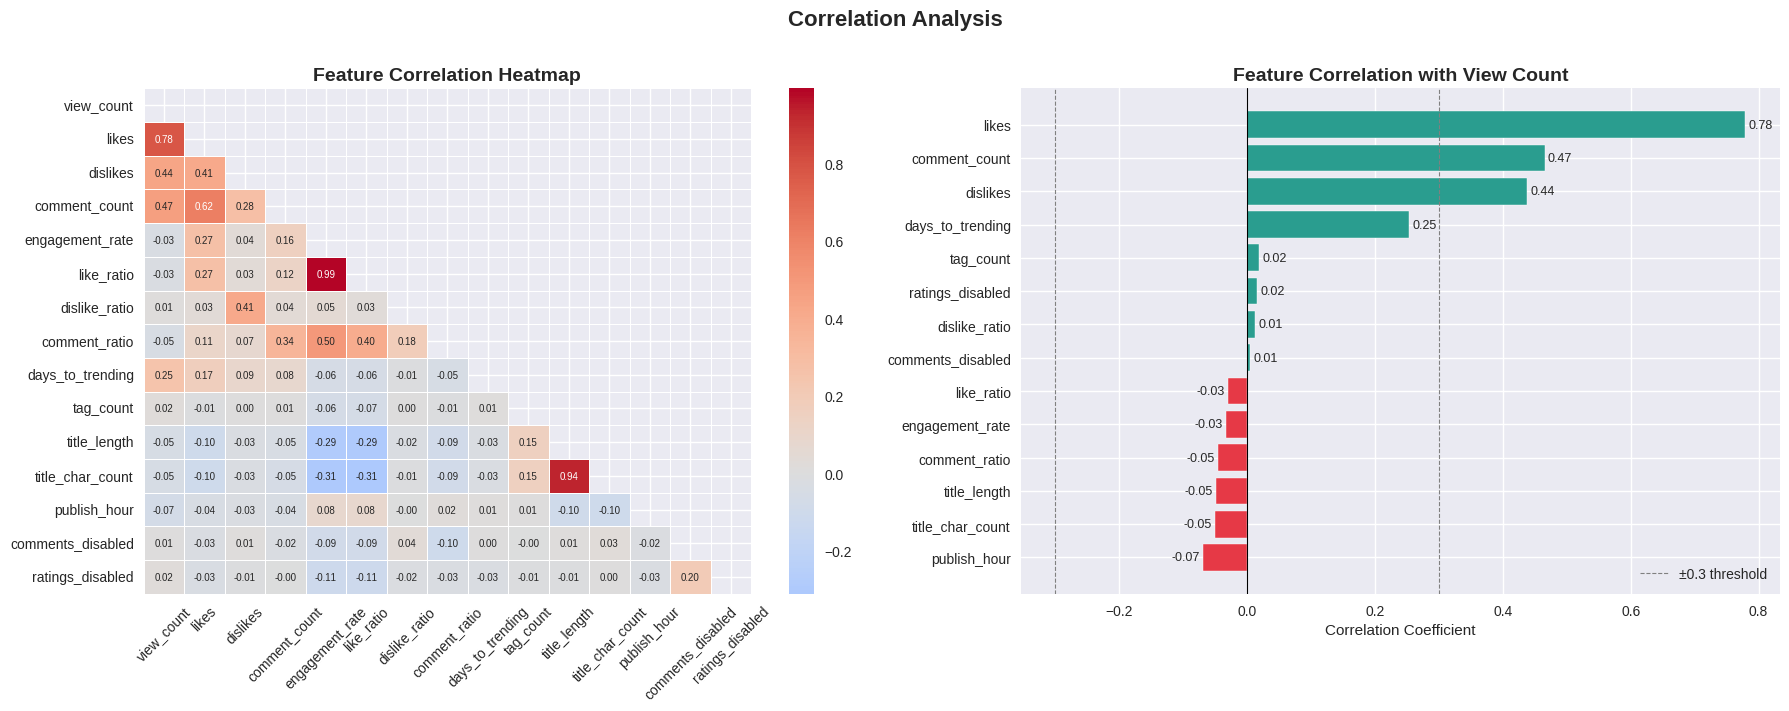

Feature Correlations with View Count:
likes                0.779553
comment_count        0.465664
dislikes             0.438030
days_to_trending     0.254025
tag_count            0.018771
ratings_disabled     0.015964
dislike_ratio        0.012310
comments_disabled    0.005222
like_ratio          -0.029666
engagement_rate     -0.033501
comment_ratio       -0.045245
title_length        -0.048540
title_char_count    -0.050656
publish_hour        -0.068280

Saved: correlation_heatmap.png


In [ ]:
# ── Correlation Heatmap ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# ── Chart 1: Full correlation heatmap ─────────────────────
corr_cols = [
    "view_count", "likes", "dislikes", "comment_count",
    "engagement_rate", "like_ratio", "dislike_ratio",
    "comment_ratio", "days_to_trending", "tag_count",
    "title_length", "title_char_count", "publish_hour",
    "comments_disabled", "ratings_disabled"
]

corr_matrix = df[corr_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, ax=axes[0],
            linewidths=0.5, linecolor="white",
            annot_kws={"size": 7})
axes[0].set_title("Feature Correlation Heatmap", fontsize=14, fontweight="bold")
axes[0].tick_params(axis="x", rotation=45)
axes[0].tick_params(axis="y", rotation=0)

# ── Chart 2: Correlation with view_count only ─────────────
view_corr = corr_matrix["view_count"].drop("view_count").sort_values()
colors_corr = ["#E63946" if v < 0 else "#2A9D8F" for v in view_corr.values]

axes[1].barh(view_corr.index, view_corr.values, color=colors_corr, edgecolor="white")
axes[1].set_title("Feature Correlation with View Count",
                   fontsize=14, fontweight="bold")
axes[1].set_xlabel("Correlation Coefficient")
axes[1].axvline(x=0, color="black", linewidth=0.8)
axes[1].axvline(x=0.3,  color="gray", linewidth=0.8, linestyle="--", label="±0.3 threshold")
axes[1].axvline(x=-0.3, color="gray", linewidth=0.8, linestyle="--")
for i, v in enumerate(view_corr.values):
    axes[1].text(v + 0.005 if v >= 0 else v - 0.005, i,
                 f"{v:.2f}", va="center",
                 ha="left" if v >= 0 else "right", fontsize=9)
axes[1].legend()

plt.suptitle("Correlation Analysis", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# Print top correlations with view_count
print("Feature Correlations with View Count:")
print("=" * 45)
print(view_corr.sort_values(ascending=False).to_string())
print("\nSaved: correlation_heatmap.png")

# PHASE E — Machine Learning

**Data Preparation for ML**

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Reload dataset to ensure 'df' is defined
df = pd.read_csv("youtube_final.csv")


# ── Select features for ML ────────────────────────────────
# Drop highly correlated duplicate (title_char_count ~ title_length = 0.94)
# Drop IDs, text columns and target leakage columns

feature_cols = [
    "likes", "dislikes", "comment_count",
    "days_to_trending", "tag_count", "title_length",
    "publish_hour", "comments_disabled", "ratings_disabled",
    "engagement_rate", "like_ratio", "dislike_ratio", "comment_ratio"
]

# ── Encode categorical features ───────────────────────────
# Encode publish_day
day_map = {
    "Monday":0, "Tuesday":1, "Wednesday":2, "Thursday":3,
    "Friday":4, "Saturday":5, "Sunday":6
}
df["publish_day_num"] = df["publish_day"].map(day_map)
feature_cols.append("publish_day_num")

# Encode category_name
le_cat = LabelEncoder()
df["category_encoded"] = le_cat.fit_transform(df["category_name"])
feature_cols.append("category_encoded")

# ── Encode target variable ────────────────────────────────
le_target = LabelEncoder()
df["success_encoded"] = le_target.fit_transform(df["success_class"])

print("Target encoding:")
for i, cls in enumerate(le_target.classes_):
    print(f"  {i} → {cls}")

# ── Prepare X and y ───────────────────────────────────────
X = df[feature_cols]
y = df["success_encoded"]

print(f"\nFeatures selected: {len(feature_cols)}")
print(f"Feature list: {feature_cols}")
print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"\nClass distribution:")
print(y.value_counts().sort_index())

# ── Train test split 80/20 ────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain size: {X_train.shape[0]} rows")
print(f"Test size:  {X_test.shape[0]} rows")

# ── Scale features ────────────────────────────────────────
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"\nData preparation complete — ready for model training!")

Target encoding:
  0 → High
  1 → Low
  2 → Medium

Features selected: 15
Feature list: ['likes', 'dislikes', 'comment_count', 'days_to_trending', 'tag_count', 'title_length', 'publish_hour', 'comments_disabled', 'ratings_disabled', 'engagement_rate', 'like_ratio', 'dislike_ratio', 'comment_ratio', 'publish_day_num', 'category_encoded']

X shape: (47076, 15)
y shape: (47076,)

Class distribution:
success_encoded
0    14123
1    14123
2    18830
Name: count, dtype: int64

Train size: 37660 rows
Test size:  9416 rows

Data preparation complete — ready for model training!


# PHASE F
***MODEL TRAINING***

MODEL 1 — LOGISTIC REGRESSION

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, f1_score,
                              precision_score, recall_score,
                              classification_report)
import time

# ── Dictionary to store results ───────────────────────────
results = {}

# ════════════════════════════════════════════════════════
# MODEL 1 — LOGISTIC REGRESSION
# ════════════════════════════════════════════════════════
print("Training Model 1: Logistic Regression...")
start = time.time()

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    multi_class="multinomial"
)
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)
lr_time = time.time() - start

results["Logistic Regression"] = {
    "model":     lr_model,
    "accuracy":  accuracy_score(y_test, lr_pred),
    "f1":        f1_score(y_test, lr_pred, average="weighted"),
    "precision": precision_score(y_test, lr_pred, average="weighted"),
    "recall":    recall_score(y_test, lr_pred, average="weighted"),
    "time":      lr_time,
    "pred":      lr_pred
}
print(f"Done in {lr_time:.2f}s — Accuracy: {results['Logistic Regression']['accuracy']:.4f}")


Training Model 1: Logistic Regression...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Done in 1.18s — Accuracy: 0.9811


MODEL 2 — RANDOM FOREST

In [ ]:
# ════════════════════════════════════════════════════════
# MODEL 2 — RANDOM FOREST
# ════════════════════════════════════════════════════════
print("\nTraining Model 2: Random Forest...")
start = time.time()

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_time = time.time() - start

results["Random Forest"] = {
    "model":     rf_model,
    "accuracy":  accuracy_score(y_test, rf_pred),
    "f1":        f1_score(y_test, rf_pred, average="weighted"),
    "precision": precision_score(y_test, rf_pred, average="weighted"),
    "recall":    recall_score(y_test, rf_pred, average="weighted"),
    "time":      rf_time,
    "pred":      rf_pred
}
print(f"Done in {rf_time:.2f}s — Accuracy: {results['Random Forest']['accuracy']:.4f}")



Training Model 2: Random Forest...
Done in 13.29s — Accuracy: 0.9758


**MODEL 3 — XGBOOST**

In [ ]:
# ════════════════════════════════════════════════════════
# MODEL 3 — XGBOOST
# ════════════════════════════════════════════════════════
print("\nTraining Model 3: XGBoost...")
start = time.time()

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="mlogloss",
    verbosity=0
)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
xgb_time = time.time() - start

results["XGBoost"] = {
    "model":     xgb_model,
    "accuracy":  accuracy_score(y_test, xgb_pred),
    "f1":        f1_score(y_test, xgb_pred, average="weighted"),
    "precision": precision_score(y_test, xgb_pred, average="weighted"),
    "recall":    recall_score(y_test, xgb_pred, average="weighted"),
    "time":      xgb_time,
    "pred":      xgb_pred
}
print(f"Done in {xgb_time:.2f}s — Accuracy: {results['XGBoost']['accuracy']:.4f}")



Training Model 3: XGBoost...
Done in 3.12s — Accuracy: 0.9895


**COMPARISON TABLE**

In [ ]:
print(f"\n{'='*65}")
print(f"MODEL COMPARISON RESULTS")
print(f"{'='*65}")
print(f"{'Model':<22} {'Accuracy':>10} {'F1 Score':>10} {'Precision':>10} {'Recall':>10} {'Time':>8}")
print(f"{'-'*65}")
for name, r in results.items():
    print(f"{name:<22} {r['accuracy']:>10.4f} {r['f1']:>10.4f} {r['precision']:>10.4f} {r['recall']:>10.4f} {r['time']:>7.2f}s")

print(f"\nBest Model by Accuracy: {max(results, key=lambda x: results[x]['accuracy'])}")
print(f"Best Model by F1 Score: {max(results, key=lambda x: results[x]['f1'])}")




MODEL COMPARISON RESULTS
Model                    Accuracy   F1 Score  Precision     Recall     Time
-----------------------------------------------------------------
Logistic Regression        0.9811     0.9811     0.9814     0.9811    1.18s
Random Forest              0.9758     0.9758     0.9759     0.9758   13.29s
XGBoost                    0.9895     0.9895     0.9895     0.9895    3.12s

Best Model by Accuracy: XGBoost
Best Model by F1 Score: XGBoost


**Detailed report for best model**


In [ ]:
# ── Detailed report for best model ────────────────────────
print(f"\nDetailed Classification Report — XGBoost:")
print("=" * 55)
print(classification_report(
    y_test, xgb_pred,
    target_names=le_target.classes_
))


Detailed Classification Report — XGBoost:
              precision    recall  f1-score   support

        High       0.99      0.99      0.99      2825
         Low       0.99      0.99      0.99      2825
      Medium       0.99      0.99      0.99      3766

    accuracy                           0.99      9416
   macro avg       0.99      0.99      0.99      9416
weighted avg       0.99      0.99      0.99      9416



**Saved all the models**

In [ ]:
import pickle

# Save all models and preprocessing objects
with open("lr_model.pkl",     "wb") as f: pickle.dump(lr_model,    f)
with open("rf_model.pkl",     "wb") as f: pickle.dump(rf_model,    f)
with open("xgb_model.pkl",    "wb") as f: pickle.dump(xgb_model,   f)
with open("scaler.pkl",       "wb") as f: pickle.dump(scaler,      f)
with open("le_target.pkl",    "wb") as f: pickle.dump(le_target,   f)
with open("le_cat.pkl",       "wb") as f: pickle.dump(le_cat,      f)

print("All models saved successfully!")
print("Files saved:")
print("  lr_model.pkl")
print("  rf_model.pkl")
print("  xgb_model.pkl")
print("  scaler.pkl")
print("  le_target.pkl")
print("  le_cat.pkl")

All models saved successfully!
Files saved:
  lr_model.pkl
  rf_model.pkl
  xgb_model.pkl
  scaler.pkl
  le_target.pkl
  le_cat.pkl


**Model Evaluation Visualisations**

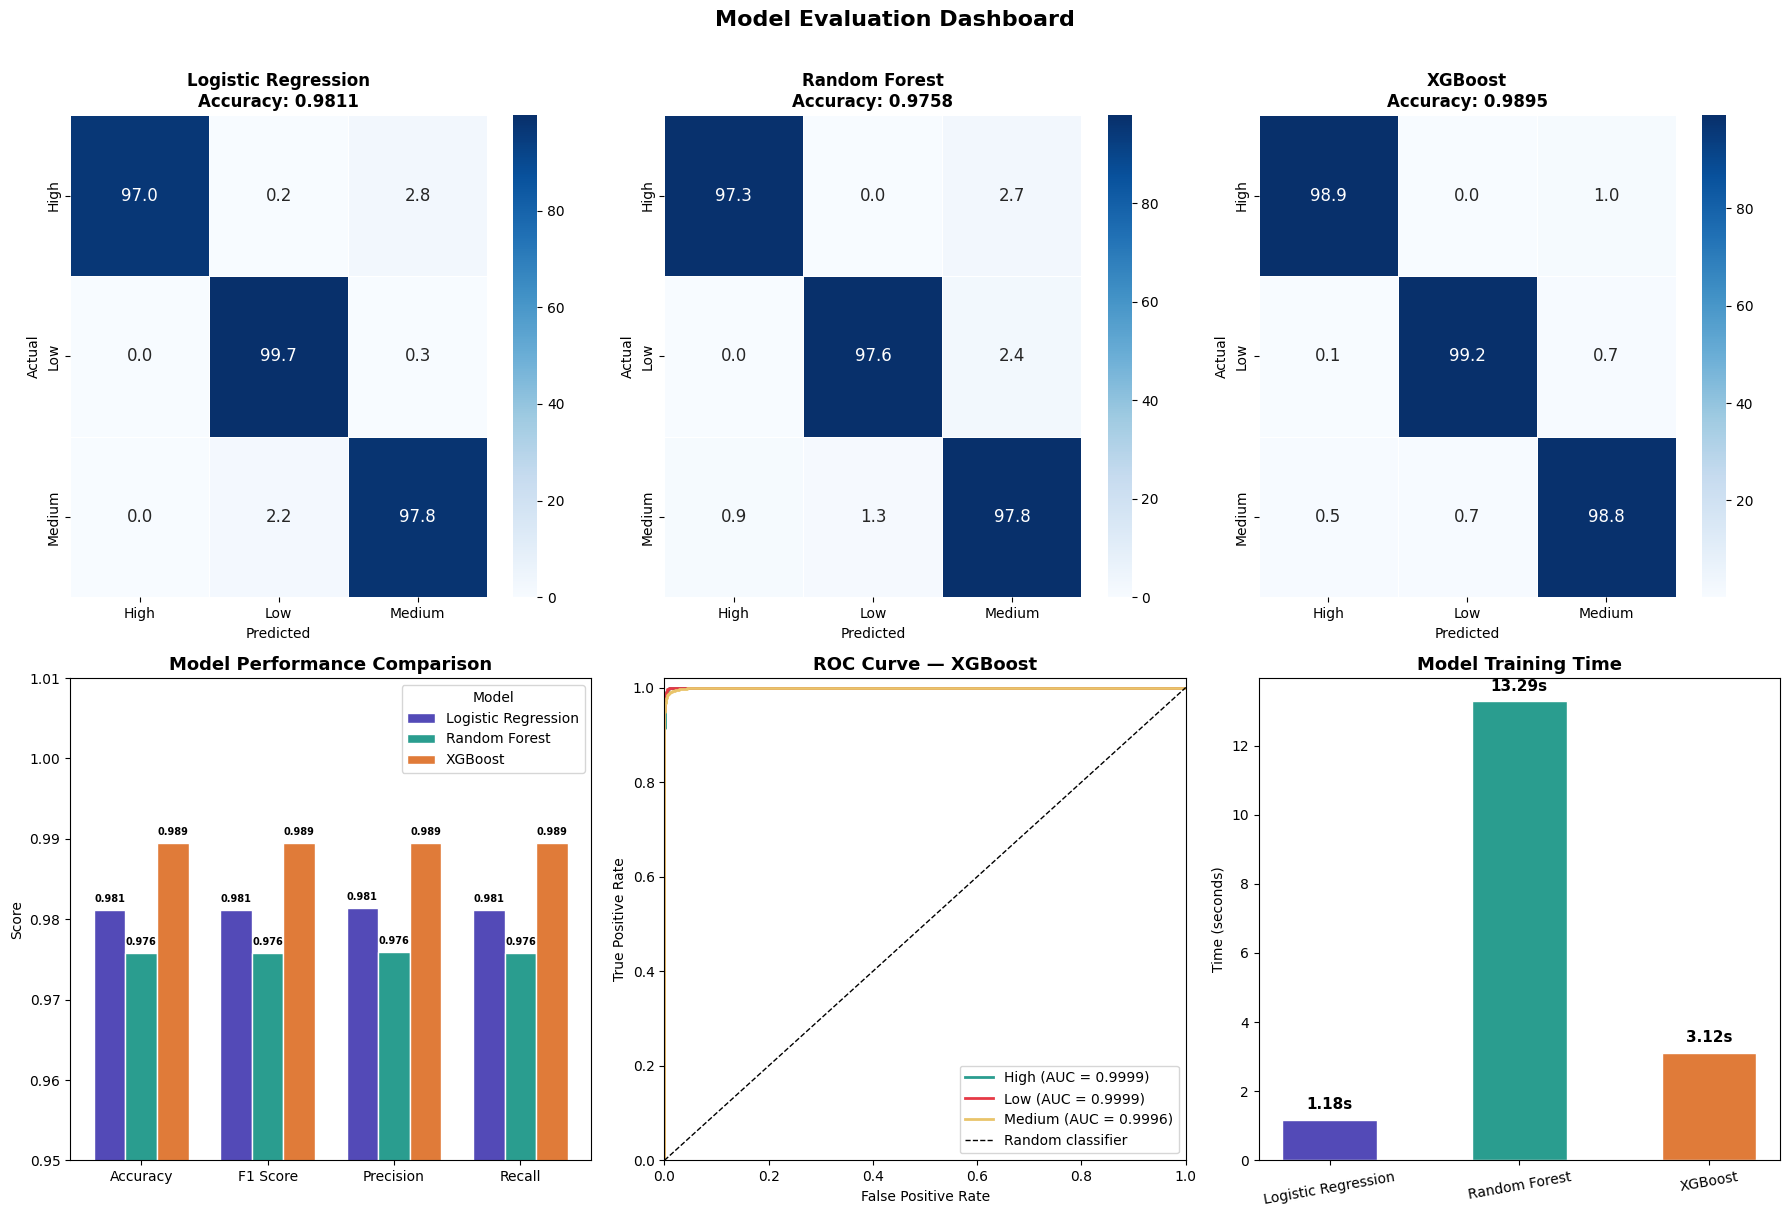

AUC-ROC Scores (XGBoost):
High       AUC: 0.9999
Low        AUC: 0.9999
Medium     AUC: 0.9996

Saved: model_evaluation.png


In [ ]:
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# ── Confusion matrices for all 3 models ───────────────────
models_preds = [
    ("Logistic Regression", lr_pred),
    ("Random Forest",       rf_pred),
    ("XGBoost",             xgb_pred)
]

for idx, (name, pred) in enumerate(models_preds):
    cm = confusion_matrix(y_test, pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis] * 100

    sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues",
                ax=axes[0, idx],
                xticklabels=le_target.classes_,
                yticklabels=le_target.classes_,
                linewidths=0.5, linecolor="white",
                annot_kws={"size": 12})
    axes[0, idx].set_title(
        f"{name}\nAccuracy: {results[name]['accuracy']:.4f}",
        fontsize=12, fontweight="bold")
    axes[0, idx].set_xlabel("Predicted")
    axes[0, idx].set_ylabel("Actual")

# ── Model comparison bar chart ────────────────────────────
metrics    = ["accuracy", "f1", "precision", "recall"]
met_labels = ["Accuracy", "F1 Score", "Precision", "Recall"]
model_names = list(results.keys())
x     = np.arange(len(metrics))
width = 0.25
colors_m = ["#534AB7", "#2A9D8F", "#E07B39"]

for i, (name, color) in enumerate(zip(model_names, colors_m)):
    vals = [results[name][m] for m in metrics]
    bars = axes[1, 0].bar(x + i*width, vals, width,
                           label=name, color=color, edgecolor="white")
    for bar, v in zip(bars, vals):
        axes[1, 0].text(bar.get_x() + bar.get_width()/2,
                        bar.get_height() + 0.001,
                        f"{v:.3f}", ha="center", fontsize=7, fontweight="bold")

axes[1, 0].set_title("Model Performance Comparison", fontsize=13, fontweight="bold")
axes[1, 0].set_xticks(x + width)
axes[1, 0].set_xticklabels(met_labels)
axes[1, 0].set_ylabel("Score")
axes[1, 0].set_ylim(0.95, 1.01)
axes[1, 0].legend(title="Model")
axes[1, 0].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.2f}"))

# ── ROC Curve for XGBoost ─────────────────────────────────
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
y_prob     = xgb_model.predict_proba(X_test)
class_colors = ["#2A9D8F", "#E63946", "#E9C46A"]

for i, (cls, color) in enumerate(zip(le_target.classes_, class_colors)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    axes[1, 1].plot(fpr, tpr, color=color, linewidth=2,
                    label=f"{cls} (AUC = {roc_auc:.4f})")

axes[1, 1].plot([0,1], [0,1], "k--", linewidth=1, label="Random classifier")
axes[1, 1].set_title("ROC Curve — XGBoost", fontsize=13, fontweight="bold")
axes[1, 1].set_xlabel("False Positive Rate")
axes[1, 1].set_ylabel("True Positive Rate")
axes[1, 1].legend()
axes[1, 1].set_xlim([0, 1])
axes[1, 1].set_ylim([0, 1.02])

# ── Training time comparison ──────────────────────────────
times    = [results[m]["time"] for m in model_names]
colors_t = ["#534AB7", "#2A9D8F", "#E07B39"]
bars     = axes[1, 2].bar(model_names, times,
                           color=colors_t, edgecolor="white", width=0.5)
axes[1, 2].set_title("Model Training Time", fontsize=13, fontweight="bold")
axes[1, 2].set_ylabel("Time (seconds)")
for bar, t in zip(bars, times):
    axes[1, 2].text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + 0.3,
                    f"{t:.2f}s", ha="center", fontsize=11, fontweight="bold")
axes[1, 2].tick_params(axis="x", rotation=10)

plt.suptitle("Model Evaluation Dashboard",
             fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("model_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Print AUC scores ──────────────────────────────────────
print("AUC-ROC Scores (XGBoost):")
print("=" * 35)
for i, cls in enumerate(le_target.classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    print(f"{cls:<10} AUC: {auc(fpr, tpr):.4f}")
print("\nSaved: model_evaluation.png")

**Feature Importance & Explainability**

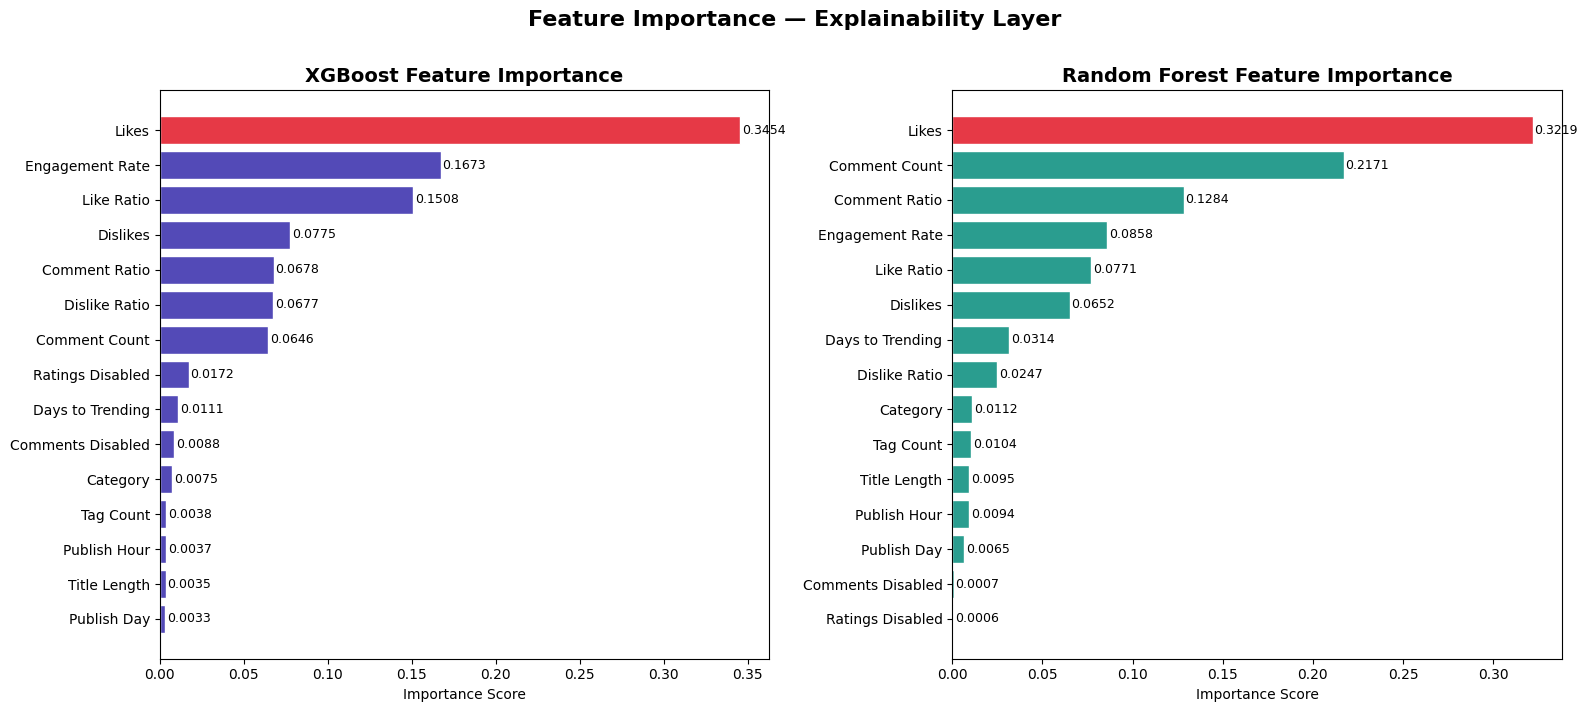

XGBoost Feature Importance Ranking:
              Feature  Importance
1               Likes      0.3454
2     Engagement Rate      0.1673
3          Like Ratio      0.1508
4            Dislikes      0.0775
5       Comment Ratio      0.0678
6       Dislike Ratio      0.0677
7       Comment Count      0.0646
8    Ratings Disabled      0.0172
9    Days to Trending      0.0111
10  Comments Disabled      0.0088
11           Category      0.0075
12          Tag Count      0.0038
13       Publish Hour      0.0037
14       Title Length      0.0035
15        Publish Day      0.0033

Top 3 most important features:
  1. Likes — 0.3454
  2. Engagement Rate — 0.1673
  3. Like Ratio — 0.1508

Least important features (consider dropping):
  13. Publish Hour — 0.0037
  14. Title Length — 0.0035
  15. Publish Day — 0.0033

Saved: feature_importance.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ── Chart 1: XGBoost Feature Importance ───────────────────
feature_names = [
    "Likes", "Dislikes", "Comment Count",
    "Days to Trending", "Tag Count", "Title Length",
    "Publish Hour", "Comments Disabled", "Ratings Disabled",
    "Engagement Rate", "Like Ratio", "Dislike Ratio",
    "Comment Ratio", "Publish Day", "Category"
]

importances = xgb_model.feature_importances_
indices     = np.argsort(importances)
colors_imp  = ["#E63946" if importances[i] == max(importances)
               else "#534AB7" for i in indices]

axes[0].barh(
    [feature_names[i] for i in indices],
    importances[indices],
    color=colors_imp, edgecolor="white"
)
axes[0].set_title("XGBoost Feature Importance",
                   fontsize=14, fontweight="bold")
axes[0].set_xlabel("Importance Score")
for i, v in enumerate(importances[indices]):
    axes[0].text(v + 0.001, i, f"{v:.4f}",
                 va="center", fontsize=9)

# ── Chart 2: Random Forest Feature Importance ─────────────
rf_importances = rf_model.feature_importances_
rf_indices     = np.argsort(rf_importances)
colors_rf      = ["#E63946" if rf_importances[i] == max(rf_importances)
                  else "#2A9D8F" for i in rf_indices]

axes[1].barh(
    [feature_names[i] for i in rf_indices],
    rf_importances[rf_indices],
    color=colors_rf, edgecolor="white"
)
axes[1].set_title("Random Forest Feature Importance",
                   fontsize=14, fontweight="bold")
axes[1].set_xlabel("Importance Score")
for i, v in enumerate(rf_importances[rf_indices]):
    axes[1].text(v + 0.001, i, f"{v:.4f}",
                 va="center", fontsize=9)

plt.suptitle("Feature Importance — Explainability Layer",
             fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Print ranked feature importance table ─────────────────
print("XGBoost Feature Importance Ranking:")
print("=" * 45)
fi_df = pd.DataFrame({
    "Feature":    feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False).reset_index(drop=True)

fi_df.index = fi_df.index + 1
fi_df["Importance"] = fi_df["Importance"].round(4)
print(fi_df.to_string())

print(f"\nTop 3 most important features:")
for i, row in fi_df.head(3).iterrows():
    print(f"  {i}. {row['Feature']} — {row['Importance']:.4f}")

print(f"\nLeast important features (consider dropping):")
for i, row in fi_df.tail(3).iterrows():
    print(f"  {i}. {row['Feature']} — {row['Importance']:.4f}")

print("\nSaved: feature_importance.png")

In [ ]:
# Fix — reset index properly
benchmarks = benchmarks.reset_index()
benchmarks = benchmarks.set_index("category_name")

# Verify categories are available
print("Available categories:")
print(benchmarks.index.tolist())

Available categories:
['Autos & Vehicles', 'Comedy', 'Education', 'Entertainment', 'Film & Animation', 'Gaming', 'Howto & Style', 'Music', 'News & Politics', 'Nonprofits & Activism', 'People & Blogs', 'Pets & Animals', 'Science & Technology', 'Sports', 'Travel & Events']


# PHASE G
**Recommendation Engine**

In [ ]:
import pandas as pd
import numpy as np

print("=" * 60)
print("YOUTUBE CREATOR RECOMMENDATION ENGINE")
print("=" * 60)

# ── Benchmark statistics per category ─────────────────────
benchmarks = df.groupby("category_name").agg(
    avg_views         = ("view_count",      "mean"),
    avg_likes         = ("likes",           "mean"),
    avg_engagement    = ("engagement_rate", "mean"),
    avg_like_ratio    = ("like_ratio",      "mean"),
    avg_comment_ratio = ("comment_ratio",   "mean"),
    avg_tag_count     = ("tag_count",       "mean"),
    avg_title_length  = ("title_length",    "mean"),
    avg_days_trending = ("days_to_trending","mean"),
    high_pct          = ("success_class",   lambda x: (x=="High").mean()*100)
).round(4)

# ── Best publish day per category ─────────────────────────
best_day = df.groupby(["category_name","publish_day"])["view_count"]\
             .mean().reset_index()
best_day = best_day.loc[best_day.groupby("category_name")["view_count"]\
                                .idxmax()][["category_name","publish_day"]]
best_day.columns = ["category_name","best_publish_day"]
benchmarks = benchmarks.reset_index()
benchmarks = benchmarks.merge(best_day, on="category_name")

# ── Best publish hour per category ────────────────────────
best_hour = df.groupby(["category_name","publish_hour"])["view_count"]\
              .mean().reset_index()
best_hour = best_hour.loc[best_hour.groupby("category_name")["view_count"]\
                                   .idxmax()][["category_name","publish_hour"]]
best_hour.columns = ["category_name","best_publish_hour"]
benchmarks = benchmarks.merge(best_hour, on="category_name")

# ── Set index AFTER all merges ────────────────────────────
benchmarks = benchmarks.set_index("category_name")

print(f"Benchmarks ready for {len(benchmarks)} categories")
print(f"Categories: {benchmarks.index.tolist()}")

# ════════════════════════════════════════════════════════
# RECOMMENDATION FUNCTION
# ════════════════════════════════════════════════════════
def get_recommendations(
    category, likes, comment_count,
    engagement_rate, tag_count, title_length,
    publish_day, publish_hour
):
    print(f"\n{'='*60}")
    print(f"RECOMMENDATIONS FOR: {category.upper()} CREATOR")
    print(f"{'='*60}")

    if category not in benchmarks.index:
        print(f"Category '{category}' not found.")
        print(f"Available: {benchmarks.index.tolist()}")
        return

    bench = benchmarks.loc[category]

    # ── Predict success class ──────────────────────────────
    day_map = {
        "Monday":0,"Tuesday":1,"Wednesday":2,"Thursday":3,
        "Friday":4,"Saturday":5,"Sunday":6
    }
    cat_encoded  = le_cat.transform([category])[0]
    like_ratio   = likes / max(1000, likes * 10)
    input_data   = pd.DataFrame([[
        likes, 0, comment_count,
        5.5, tag_count, title_length,
        publish_hour, 0, 0,
        engagement_rate, like_ratio, 0,
        comment_count / max(likes * 10, 1),
        day_map.get(publish_day, 4), cat_encoded
    ]], columns=feature_cols)

    pred_class  = xgb_model.predict(input_data)[0]
    pred_label  = le_target.inverse_transform([pred_class])[0]
    pred_proba  = xgb_model.predict_proba(input_data)[0]
    confidence  = max(pred_proba) * 100

    print(f"\n📊 PREDICTED PERFORMANCE: {pred_label.upper()}")
    print(f"   Confidence: {confidence:.1f}%")
    for cls, prob in zip(le_target.classes_, pred_proba):
        bar = "█" * int(prob * 20)
        print(f"   {cls:<8} {bar:<20} {prob*100:.1f}%")

    # ── Engagement analysis ────────────────────────────────
    print(f"\n📈 ENGAGEMENT ANALYSIS vs {category} Benchmark:")
    print(f"   {'Metric':<22} {'Your Value':>12} {'Benchmark':>12} {'Status':>10}")
    print(f"   {'-'*58}")

    metrics_check = [
        ("Engagement Rate %",  engagement_rate,  bench["avg_engagement"],   "%"),
        ("Like Ratio",         like_ratio,        bench["avg_like_ratio"],   ""),
        ("Tag Count",          tag_count,         bench["avg_tag_count"],    ""),
        ("Title Length (wds)", title_length,      bench["avg_title_length"], ""),
    ]

    for metric, val, bmark, unit in metrics_check:
        status = "✅ Above" if val >= bmark else "⚠️ Below"
        print(f"   {metric:<22} {str(round(val,3))+unit:>12} "
              f"{str(round(bmark,3))+unit:>12} {status:>10}")

    # ── Timing recommendations ────────────────────────────
    print(f"\n⏰ TIMING RECOMMENDATIONS for {category}:")
    print(f"   Best publish day:  {bench['best_publish_day']}")
    print(f"   Best publish hour: {int(bench['best_publish_hour']):02d}:00")
    print(f"   Your publish day:  {publish_day} "
          + ("✅" if publish_day == bench["best_publish_day"] else "⚠️ Consider changing"))
    print(f"   Your publish hour: {publish_hour:02d}:00 "
          + ("✅" if publish_hour == bench["best_publish_hour"] else "⚠️ Consider changing"))

    # ── Specific recommendations ──────────────────────────
    print(f"\n💡 SPECIFIC RECOMMENDATIONS:")
    recs = []

    if engagement_rate < bench["avg_engagement"]:
        recs.append(f"Increase engagement — target above "
                    f"{bench['avg_engagement']:.2f}% (your category benchmark). "
                    f"Add calls-to-action in your video.")

    if tag_count < bench["avg_tag_count"]:
        recs.append(f"Add more tags — you have {tag_count} tags, "
                    f"benchmark is {bench['avg_tag_count']:.0f} tags.")

    if tag_count > bench["avg_tag_count"] * 1.5:
        recs.append(f"Reduce tags — too many tags can hurt discoverability. "
                    f"Target around {bench['avg_tag_count']:.0f} tags.")

    if title_length < bench["avg_title_length"]:
        recs.append(f"Lengthen your title — target {bench['avg_title_length']:.0f} "
                    f"words (current: {title_length} words).")

    if title_length > bench["avg_title_length"] * 1.3:
        recs.append(f"Shorten your title — target around "
                    f"{bench['avg_title_length']:.0f} words for this category.")

    if publish_day != bench["best_publish_day"]:
        recs.append(f"Switch publish day to {bench['best_publish_day']} — "
                    f"highest average views for {category} category.")

    if publish_hour != bench["best_publish_hour"]:
        recs.append(f"Switch publish hour to "
                    f"{int(bench['best_publish_hour']):02d}:00 — "
                    f"best performing time slot for {category}.")

    if not recs:
        recs.append("Your video settings are well optimised — keep it up!")

    for i, rec in enumerate(recs, 1):
        print(f"   {i}. {rec}")

    # ── Category insight ──────────────────────────────────
    print(f"\n🎯 CATEGORY INSIGHT:")
    print(f"   {bench['high_pct']:.1f}% of {category} videos achieve High performance")
    print(f"   Average views in this category: {bench['avg_views']/1e6:.2f}M")
    print(f"   Your predicted class: {pred_label}")
    print(f"{'='*60}")

# ════════════════════════════════════════════════════════
# TEST WITH EXAMPLE CREATORS
# ════════════════════════════════════════════════════════
# Example 1 — Gaming creator
get_recommendations(
    category        = "Gaming",
    likes           = 5000,
    comment_count   = 300,
    engagement_rate = 4.5,
    tag_count       = 10,
    title_length    = 6,
    publish_day     = "Wednesday",
    publish_hour    = 14
)

# Example 2 — Music creator
get_recommendations(
    category        = "Music",
    likes           = 50000,
    comment_count   = 2000,
    engagement_rate = 7.2,
    tag_count       = 20,
    title_length    = 5,
    publish_day     = "Friday",
    publish_hour    = 9
)

YOUTUBE CREATOR RECOMMENDATION ENGINE
Benchmarks ready for 15 categories
Categories: ['Autos & Vehicles', 'Comedy', 'Education', 'Entertainment', 'Film & Animation', 'Gaming', 'Howto & Style', 'Music', 'News & Politics', 'Nonprofits & Activism', 'People & Blogs', 'Pets & Animals', 'Science & Technology', 'Sports', 'Travel & Events']

RECOMMENDATIONS FOR: GAMING CREATOR

📊 PREDICTED PERFORMANCE: LOW
   Confidence: 100.0%
   High                          0.0%
   Low      ███████████████████  100.0%
   Medium                        0.0%

📈 ENGAGEMENT ANALYSIS vs Gaming Benchmark:
   Metric                   Your Value    Benchmark     Status
   ----------------------------------------------------------
   Engagement Rate %              4.5%       5.242%   ⚠️ Below
   Like Ratio                      0.1        0.049    ✅ Above
   Tag Count                        10       16.721   ⚠️ Below
   Title Length (wds)                6        8.157   ⚠️ Below

⏰ TIMING RECOMMENDATIONS for Gaming:
 

In [ ]:
benchmarks.reset_index().to_excel("category_benchmarks.xlsx", index=False)
print("Saved: category_benchmarks.xlsx")

Saved: category_benchmarks.xlsx


**prepare dataset for dashboard **

In [ ]:
# Save a clean dashboard-ready Excel file
dashboard_df = df[[
    "video_id", "title", "channelTitle", "category_name",
    "publish_day", "publish_hour", "publish_month", "publish_year",
    "view_count", "likes", "dislikes", "comment_count",
    "engagement_rate", "like_ratio", "dislike_ratio", "comment_ratio",
    "days_to_trending", "tag_count", "title_length",
    "success_class", "comments_disabled", "ratings_disabled"
]].copy()

# Make dates readable
dashboard_df["publish_hour_label"] = dashboard_df["publish_hour"].apply(
    lambda x: f"{x:02d}:00"
)

dashboard_df.to_excel("youtube_dashboard.xlsx", index=False)
print(f"Dashboard file saved: {len(dashboard_df)} rows, {len(dashboard_df.columns)} columns")
print("Ready to import into Power BI or Plotly!")

Dashboard file saved: 47076 rows, 23 columns
Ready to import into Power BI or Plotly!
